In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions

utilities.set_plot_style()
%matplotlib inline

In [2]:
channel_name = 'cr_Zmumu_noLJ_noMu_cut'
output_signal_2mu = functions.load_output("signal_2mu", channel_name)
output_signal_4mu = functions.load_output("signal_4mu", channel_name)


In [9]:
yaml_file_path = '../../configs/ntuples/signal_2mu2e_v10.yaml'
# Open and read the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)
signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())
masses = [200, 500, 800, 1000]
signals = [
    signal for signal in signals_all
    if any(f'{mass}GeV_' in signal for mass in masses)
]

masses = [ 500]
signal = [
    signal for signal in signals_all
    if any(f'{mass}GeV_' in signal for mass in masses)
]

for x in signal:
    print(f"'{x}',")

'2Mu2E_500GeV_0p25GeV_0p004mm',
'2Mu2E_500GeV_0p25GeV_0p04mm',
'2Mu2E_500GeV_0p25GeV_0p4mm',
'2Mu2E_500GeV_0p25GeV_2p0mm',
'2Mu2E_500GeV_0p25GeV_4p0mm',
'2Mu2E_500GeV_1p2GeV_0p019mm',
'2Mu2E_500GeV_1p2GeV_0p19mm',
'2Mu2E_500GeV_1p2GeV_1p9mm',
'2Mu2E_500GeV_1p2GeV_9p6mm',
'2Mu2E_500GeV_1p2GeV_19p0mm',
'2Mu2E_500GeV_5p0GeV_0p08mm',
'2Mu2E_500GeV_5p0GeV_0p8mm',
'2Mu2E_500GeV_5p0GeV_8p0mm',
'2Mu2E_500GeV_5p0GeV_40p0mm',
'2Mu2E_500GeV_5p0GeV_80p0mm',


In [7]:
# signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())


'4Mu_500GeV_0p25GeV_0p004mm',
'4Mu_500GeV_0p25GeV_0p04mm',
'4Mu_500GeV_0p25GeV_0p4mm',
'4Mu_500GeV_0p25GeV_2p0mm',
'4Mu_500GeV_0p25GeV_4p0mm',
'4Mu_500GeV_1p2GeV_0p019mm',
'4Mu_500GeV_1p2GeV_0p19mm',
'4Mu_500GeV_1p2GeV_1p9mm',
'4Mu_500GeV_1p2GeV_9p6mm',
'4Mu_500GeV_1p2GeV_19p0mm',
'4Mu_500GeV_5p0GeV_0p08mm',
'4Mu_500GeV_5p0GeV_0p8mm',
'4Mu_500GeV_5p0GeV_8p0mm',
'4Mu_500GeV_5p0GeV_40p0mm',
'4Mu_500GeV_5p0GeV_80p0mm',


In [ ]:
S = [
'4Mu_500GeV_0p25GeV_0p04mm',
'4Mu_500GeV_0p25GeV_2p0mm',
'4Mu_500GeV_1p2GeV_0p19mm',
'4Mu_500GeV_1p2GeV_9p6mm',
'4Mu_500GeV_5p0GeV_0p8mm',
'4Mu_500GeV_5p0GeV_40p0mm',
'2Mu2E_500GeV_0p25GeV_2p0mm',
'2Mu2E_500GeV_1p2GeV_0p19mm',
'2Mu2E_500GeV_1p2GeV_9p6mm',
'2Mu2E_500GeV_5p0GeV_0p8mm',
'2Mu2E_500GeV_5p0GeV_40p0mm',
]

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'None'),
  Text(1, 0, 'pass triggers'),
  Text(2, 0, 'PV filter'),
  Text(3, 0, '>=2 muons (pf or dsa) pT > 26 GeV'),
  Text(4, 0, 'all cosAlpha(mu, mu) > -0.99'),
  Text(5, 0, 'pass flags'),
  Text(6, 0, '86 <= inv(Mu_0, Mu_1) <= 96')])

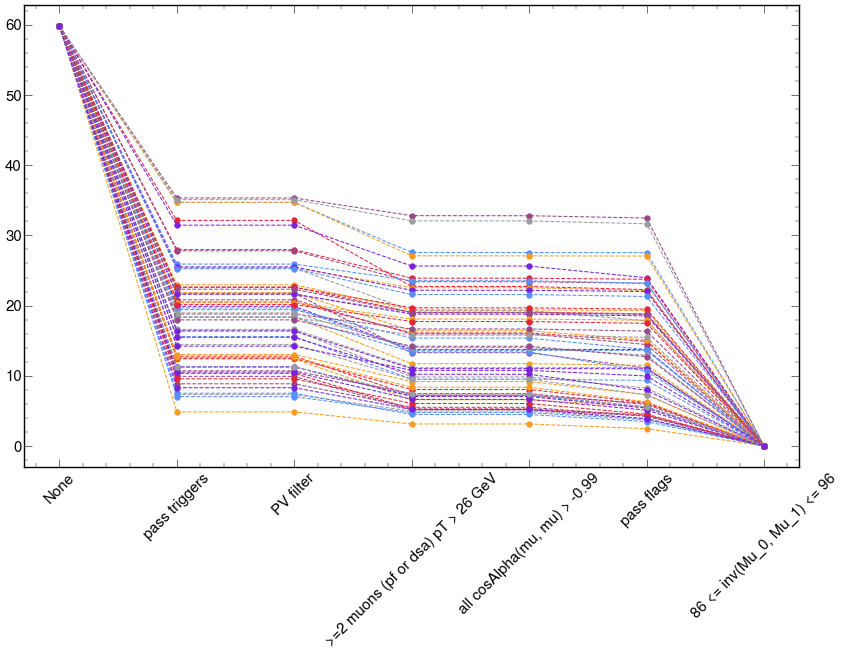

In [4]:
plt.figure(figsize=(20, 12))
for j, s in enumerate(signals):
    label = functions.get_signal_label(s)
    if label[0]=="2":
        cutflow= output_signal_2mu["out"][s]["cutflow"][channel_name]
    elif label[0] == "4":
        cutflow= output_signal_4mu["out"][s]["cutflow"][channel_name]
    else:
        print(f"cutflow not found for {s}")
    cut, N = functions.get_cutflow_list(cutflow)
    # color = colors[j]
    plt.plot(cut,N, marker='o', linestyle = "--", markersize =8, label =label)
plt.xticks(rotation=45)
# plt.legend(ncol=4)

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'None'),
  Text(1, 0, 'pass triggers'),
  Text(2, 0, 'PV filter'),
  Text(3, 0, '>=2 muons (pf or dsa) pT > 26 GeV'),
  Text(4, 0, 'all cosAlpha(mu, mu) > -0.99'),
  Text(5, 0, 'pass flags'),
  Text(6, 0, '86 <= inv(Mu_0, Mu_1) <= 96')])

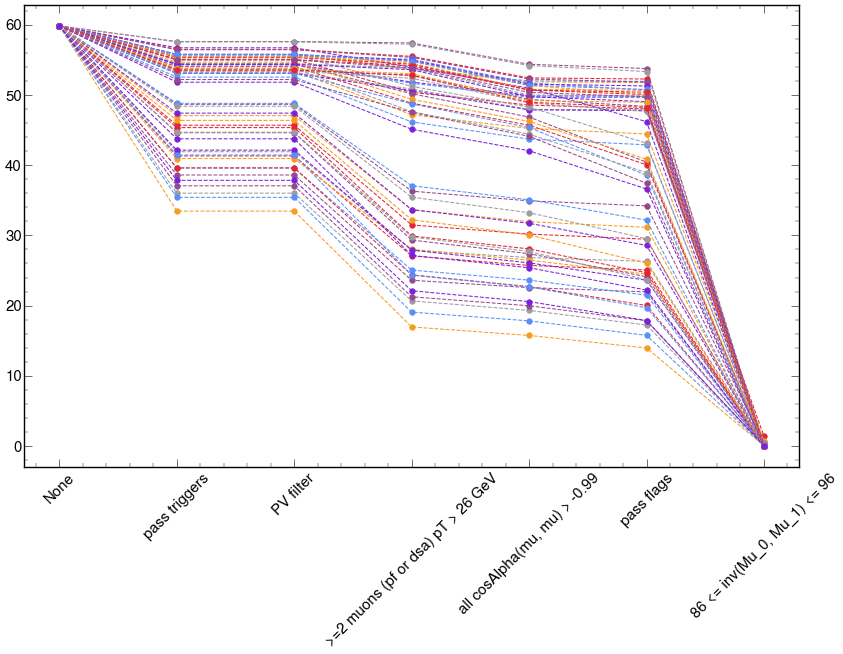

In [5]:
yaml_file_path = '../../configs/ntuples/signal_4mu_v10.yaml'
# Open and read the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)
signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())
masses = [200, 500, 800, 1000]
signals = [
    signal for signal in signals_all
    if any(f'{mass}GeV_' in signal for mass in masses)
]
plt.figure(figsize=(20, 12))
for j, s in enumerate(signals):
    label = functions.get_signal_label(s)
    if label[0]=="2":
        cutflow= output_signal_2mu["out"][s]["cutflow"][channel_name]
    elif label[0] == "4":
        cutflow= output_signal_4mu["out"][s]["cutflow"][channel_name]
    else:
        print(f"cutflow not found for {s}")
    cut, N = functions.get_cutflow_list(cutflow)
    # color = colors[j]
    plt.plot(cut,N, marker='o', linestyle = "--", markersize =8, label =label)
plt.xticks(rotation=45)
# plt.legend(ncol=4)